# Expectation values: the Sampler versus the Estimator

Notebook 08 ended by averaging the cost of a Hamiltonian over all the shots of
a circuit. Every application in Units 2 and 3 needs such an average: the
energy of a molecule, or the expected cost of the bitstrings a circuit
returns. But a quantum computer returns only bitstrings, from Z-basis
measurements. The cost in Notebook 08 was diagonal, so every bitstring had a
cost to look up. Many operators are not diagonal.

This notebook asks: what is the average value of an operator in a given
state, how do we get it from counts, even for an operator such as $X$ whose
eigenvectors are not bitstrings, and how uncertain is the result? Then it
hands the same job to a Qiskit object that does the bookkeeping for us.

## Before you start

This notebook uses:

- the Sampler, PUBs, the scatter rule, and the readout effect (a 1 is misread
  as 0 more often than the reverse) ([Notebook 00](00_Bits_and_Basis_States.ipynb));
- the eigenvalues $+1$ of $|0\rangle$ and $-1$ of $|1\rangle$ under $Z$, and
  the Z-basis measurement ([Notebook 01](01_One_Bit_Operators.ipynb));
- operators that commute ($AB = BA$) and the mixed-product rule for tensor
  products ([Notebook 02](02_Reversible_Logic.ipynb));
- amplitudes, the Born rule for one and for several qubits, inner products
  and overlaps, $H$, and `Statevector`
  ([Notebook 04](04_Amplitudes_and_Phase.ipynb));
- the X-basis measurement ($H$, then a Z-basis measurement) and the Y-basis
  measurement ([Notebook 06](06_Interference_H_vs_SX.ipynb));
- $R_y(\theta)|0\rangle = \cos(\theta/2)|0\rangle + \sin(\theta/2)|1\rangle$,
  circuit parameters, and swept PUBs ([Notebook 07](07_Rotations.ipynb));
- Pauli strings and their Qiskit labels, Hermitian operators, Hamiltonians
  (written $\mathcal{H}$ in general, with a bare $H$ kept for the Hadamard
  gate), `SparsePauliOp`, and the penalty Hamiltonian
  $H_{\text{penalty}} = \tfrac12(I + Z_1Z_0)$
  ([Notebook 08](08_Pauli_Sums.ipynb)).

From probability it uses the mean, variance, and standard deviation.

Quick check:

1. What is the probability of measuring 0 for $R_y(\theta)|0\rangle$?
2. A quantity is $+1$ with probability 0.7 and $-1$ with probability 0.3.
   What is its mean?
3. Which qubit does the `Z` in the label `"ZI"` act on?

Answers: $\cos^2(\theta/2)$; $0.7 - 0.3 = 0.4$; qubit 1.

After this notebook you will be able to:

1. Compute the average measured value of $Z$, of $X$, or of a sum of Pauli
   strings, for a given state, both by hand and from counts.
2. Estimate how uncertain such an average is for a given number of shots.
3. Decide how many differently measured circuits a sum of Pauli strings
   needs.
4. Get the same average from a Qiskit primitive that takes the operator
   directly, and compare it with the hand computation.

## Setup

The same setup as every notebook in this unit. `precision` is used for the
first time here.

In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# _runtime.py (in ../scripts) decides where circuits run:
# Aer, and IBM hardware if asked.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _runtime import get_targets

np.set_printoptions(precision=3, suppress=True)

SETTINGS = SimpleNamespace(
    shots=4096,                  # shots per circuit (Sampler jobs)
    precision=0.02,              # target standard error (Estimator jobs)
    backend="ibm_rensselaer",
    name="default",              # saved IBM account name
    skip_hardware=True,          # set to False to also run on IBM hardware
    poll_interval=20,            # seconds between hardware status checks
)
targets = get_targets(SETTINGS)
print("Running on:", [t.label for t in targets])

Running on: ['aer']


## Expectation values

A single shot of a Z-basis measurement returns 0 or 1. Read as an
eigenvalue of $Z$, that is $+1$ or $-1$ (Notebook 01: a bit $x$ has
eigenvalue $1 - 2x$). Over many shots the natural summary is the mean. For
example, 4096 shots with 3000 zeros and 1096 ones have mean
$(3000 \cdot (+1) + 1096 \cdot (-1))/4096 = 0.465$.

An *observable* is a Hermitian operator that we measure. Each shot returns
one of its eigenvalues, and the probability of each eigenvalue is the
probability of finding the state in the corresponding eigenvector, the
overlap $|\langle v|\psi\rangle|^2$ of Notebook 04 (the Born rule, with the
eigenvectors of the observable in place of $|0\rangle$ and $|1\rangle$). For
$Z$ the eigenvectors are $|0\rangle$ and $|1\rangle$, so a Z-basis
measurement is a measurement of the observable $Z$.

Two refinements matter on several qubits. First, several eigenvectors can
share one eigenvalue; then the probability of that eigenvalue is the sum of
the probabilities of those eigenvectors. Second, a Pauli string made only of
$Z$s and $I$s has the bitstrings as its eigenvectors: $Z_1Z_0$ is $+1$ on the
even-parity strings $00$, $11$ and $-1$ on $01$, $10$ (Notebook 07). So a
Z-basis measurement of every qubit measures it, and by the Born rule for
several qubits (Notebook 04), $P(+1)$ is the total probability of the
bitstrings with eigenvalue $+1$. For letters $X$ and $Y$ a change of basis on
the qubits concerned comes first; the section on sharing circuits below says
how.

The *expectation value* of an observable $O$ in the state $|\psi\rangle$ is

$$\langle O\rangle = \langle\psi|O|\psi\rangle = \sum_\lambda \lambda\, P(\lambda),$$

where the sum runs over the eigenvalues $\lambda$ of $O$ and $P(\lambda)$ is
the probability of measuring $\lambda$. In words: the average result over
many shots, which the matrix product $\langle\psi|O|\psi\rangle$ gives
without running anything.

Why the matrix product equals the average: the eigenvectors $|v_k\rangle$ of
a Hermitian operator can be chosen orthonormal (a linear-algebra result we
take as given), so write $|\psi\rangle = \sum_k b_k |v_k\rangle$ with
$O|v_k\rangle = \lambda_k |v_k\rangle$. Then
$O|\psi\rangle = \sum_k \lambda_k b_k |v_k\rangle$, and the inner product with
$|\psi\rangle$ leaves $\langle\psi|O|\psi\rangle = \sum_k \lambda_k |b_k|^2$,
because $\langle v_j|v_k\rangle$ is 1 for $j = k$ and 0 otherwise. Each
$|b_k|^2 = |\langle v_k|\psi\rangle|^2$ is the probability of finding
$|v_k\rangle$; grouping the $k$ that share an eigenvalue gives
$\sum_\lambda \lambda P(\lambda)$.

### Example 1: $\langle Z\rangle$ for any one-qubit state

**Problem.** For $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$, compute
$\langle\psi|Z|\psi\rangle$ and relate it to the counts of a Z-basis
measurement.

**Plan.** Apply $Z$, take the inner product with $|\psi\rangle$, and compare
with $\sum_\lambda \lambda P(\lambda)$.

**Solution.**

**Subgoal 1: the matrix product.**

1. Apply $Z = \mathrm{diag}(1, -1)$: $Z|\psi\rangle = \alpha|0\rangle - \beta|1\rangle$.
2. Take the inner product, conjugating the left vector (Notebook 04):
   $\langle\psi|Z|\psi\rangle = \bar\alpha\alpha - \bar\beta\beta = |\alpha|^2 - |\beta|^2$.

**Subgoal 2: the counts.**

3. By the Born rule, $|\alpha|^2 = P(0)$ and $|\beta|^2 = P(1)$, so
   $\langle Z\rangle = P(0) - P(1)$, which is $\sum_\lambda \lambda P(\lambda)$
   with $\lambda = +1$ for outcome 0 and $-1$ for outcome 1.
4. From $N$ shots with $n_0$ zeros and $n_1$ ones, estimate the probabilities
   by $n_0/N$ and $n_1/N$: $\langle Z\rangle \approx (n_0 - n_1)/N$.

**Check.** For $|0\rangle$, $\langle Z\rangle = 1$, and every shot gives
$+1$. For $|+\rangle$, $\langle Z\rangle = \tfrac12 - \tfrac12 = 0$.

**Takeaway.** $\langle Z\rangle$ is the fraction of zeros minus the fraction
of ones. It is a number between $-1$ and $1$, and it is not one of the
possible results of a single shot unless it equals $\pm1$.

To measure $X$, change basis first (Notebook 06): apply $H$ and measure in
the Z basis. Outcome 0 then means the state was found in $|+\rangle$, the
eigenvector of $X$ with eigenvalue $+1$, and outcome 1 means $|-\rangle$,
with eigenvalue $-1$. So the same formula $(n_0 - n_1)/N$, applied to the
counts after the $H$, estimates $\langle X\rangle$. For $Y$, the change of
basis is $S^\dagger$ followed by $H$.

Expectation values add. The inner product is linear, so for any two
observables $\langle A + B\rangle = \langle A\rangle + \langle B\rangle$, and
$\langle cA\rangle = c\langle A\rangle$ for a number $c$. A Hamiltonian
written as a Pauli sum $\mathcal{H} = \sum_P c_P P$ (Notebook 08) therefore
has $\langle \mathcal{H}\rangle = \sum_P c_P \langle P\rangle$: measure each
Pauli string, then add with the weights.

### Example 2: $\langle Z\rangle$ and $\langle X\rangle$ for $R_y(\theta)|0\rangle$

**Problem.** For $|\psi\rangle = R_y(\theta)|0\rangle$, compute $\langle Z\rangle$,
$\langle X\rangle$, and $\langle Z + X\rangle$.

**Plan.** Use the amplitudes $\cos(\theta/2)$ and $\sin(\theta/2)$
(Notebook 07), Example 1 for $Z$, a direct matrix product for $X$, and
linearity for the sum.

**Solution.**

**Subgoal 1: $\langle Z\rangle$.**

1. By Example 1, $\langle Z\rangle = \cos^2(\theta/2) - \sin^2(\theta/2)$.
2. By the double-angle formula $\cos^2 u - \sin^2 u = \cos 2u$:
   $\langle Z\rangle = \cos\theta$.

**Subgoal 2: $\langle X\rangle$.**

3. $X$ swaps the two amplitudes: $X|\psi\rangle = \sin(\theta/2)|0\rangle + \cos(\theta/2)|1\rangle$.
4. The amplitudes are real, so the inner product is
   $\cos(\theta/2)\sin(\theta/2) + \sin(\theta/2)\cos(\theta/2) = 2\sin(\theta/2)\cos(\theta/2)$.
5. By $2\sin u\cos u = \sin 2u$: $\langle X\rangle = \sin\theta$.

**Subgoal 3: the sum.**

6. By linearity, $\langle Z + X\rangle = \cos\theta + \sin\theta$.

**Check.** Notebook 07 found the X-basis probability $P(0) = (1 + \sin\theta)/2$
for this state. Then $\langle X\rangle = P(0) - P(1) = 2P(0) - 1 = \sin\theta$,
the same answer by an independent route. At $\theta = \pi/2$,
$\langle Z + X\rangle = 1$, and at $\theta = \pi/4$ it reaches its largest
value, $\sqrt2 \approx 1.414$.

**Takeaway.** For a sum of Pauli strings, compute (or measure) each term's
expectation value separately and add them with their coefficients.

In [2]:
from qiskit.circuit.library import RYGate
from qiskit.quantum_info import Operator

for theta in [0.4, 2.0]:
    state = Statevector(Operator(RYGate(theta)).data @ np.array([1, 0]))
    z = state.expectation_value(SparsePauliOp("Z")).real
    x = state.expectation_value(SparsePauliOp("X")).real
    cos, sin = np.cos(theta), np.sin(theta)
    print(f"theta = {theta}:  <Z> = {z:+.4f} (cos = {cos:+.4f})"
          f"   <X> = {x:+.4f} (sin = {sin:+.4f})")

theta = 0.4:  <Z> = +0.9211 (cos = +0.9211)   <X> = +0.3894 (sin = +0.3894)
theta = 2.0:  <Z> = -0.4161 (cos = -0.4161)   <X> = +0.9093 (sin = +0.9093)


`Statevector.expectation_value(observable)` computes
$\langle\psi|O|\psi\rangle$ exactly, without shots.

A common mistake is to think that an expectation value is a result that
shows up in the shots, the way "expected" sometimes means "most likely".
That is wrong. If $\langle Z\rangle = 0.465$, no shot ever returns 0.465:
every shot returns $+1$ or $-1$, and 0.465 is their average. The mistake is
tempting because of the everyday meaning of the word, and because for
bitstrings, as in Notebooks 00 to 03, the expectation value of $Z$ is
always $\pm1$, a possible result.

**Check.** What are $\langle Z\rangle$ and $\langle X\rangle$ for $|-\rangle$?

## Standard error

An average from a finite number of shots scatters around the true
expectation value. How large is that scatter?

The *standard error* of an average of $N$ independent shots is the standard
deviation of one shot divided by $\sqrt N$:
$\sqrt{\mathrm{variance}/N}$. In words: the typical distance between the
average from $N$ shots and the exact expectation value.

This is the scatter of Notebook 00, now derived. A fraction $p$ is the
average of a shot that is 1 with probability $p$ and 0 otherwise. That shot
has mean $p$ and variance $p - p^2 = p(1-p)$, so its standard error is
$\sqrt{p(1-p)/N}$, the scatter formula. The scatter rule of Notebook 00
applies to every standard error: most runs land within twice it, and a
difference of more than three times it is a real effect.

For a Pauli observable $P$, each shot gives $s = \pm1$, so $s^2 = 1$ on every
shot. The variance of one shot is the mean of $s^2$ minus the square of the
mean of $s$:

$$\mathrm{var} = 1 - \langle P\rangle^2, \qquad \text{standard error} = \sqrt{\frac{1 - \langle P\rangle^2}{N}}.$$

When an observable is a sum of terms measured in separate, independent
circuits, their variances add. For $Z + X$ measured with $N$ shots each, the
standard error of the sum is $\sqrt{(1 - \langle Z\rangle^2)/N + (1 - \langle X\rangle^2)/N}$.

### Example 3: the uncertainty of $\langle Z\rangle$ from 4096 shots

**Problem.** A Z-basis measurement gives 3000 zeros and 1096 ones in
$N = 4096$ shots. Estimate $\langle Z\rangle$ and its standard error.

**Plan.** Use $(n_0 - n_1)/N$, then the formula above. Check against the
scatter of a probability, $\sqrt{p(1-p)/N}$, from Notebook 00.

**Solution.**

1. $\langle Z\rangle \approx (3000 - 1096)/4096 = 1904/4096 = 0.4648$.
2. Variance of one shot: $1 - 0.4648^2 = 1 - 0.2161 = 0.7839$.
3. Standard error: $\sqrt{0.7839/4096} = \sqrt{1.914\times10^{-4}} = 0.0138$.

So $\langle Z\rangle = 0.465 \pm 0.014$.

**Check.** $\langle Z\rangle = 2p - 1$ with $p = P(0) = 3000/4096 = 0.7324$.
Its scatter is twice the scatter of $p$:
$2\sqrt{0.7324 \times 0.2676/4096} = 2 \times 0.00692 = 0.0138$. The two
routes agree, because $1 - (2p-1)^2 = 4p(1-p)$.

**Takeaway.** The standard error falls as $1/\sqrt N$: four times as many
shots halve it. With 4096 shots it is at most $1/\sqrt{4096} = 0.016$, the
value at $\langle P\rangle = 0$.

**Check.** How many shots give a standard error of at most 0.005 for any
state?

## Which terms can share a circuit

$\langle Z + X\rangle$ needed two circuits, one per term, because $Z$ needs
no change of basis and $X$ needs an $H$. Could one circuit ever measure two
terms at once?

Two operators commute when $AB = BA$ (Notebook 02). $Z$ and $X$ do not:
$ZX = iY$ but $XZ = -iY$ (the products from Notebook 08), so $ZX = -XZ$.
Linear algebra gives the rule that matters here, a result we take as given:
Hermitian operators that commute have a common set of eigenvectors, so a
single measurement in those eigenvectors gives the results of both.
Operators that do not commute have no such common set, and no single
measurement gives both.

For Pauli strings there is a sufficient test that looks only at the letters.
Two Pauli strings are *qubit-wise commuting* when, on every qubit, their
letters are equal or one of them is $I$. Such strings can share one circuit:
on each qubit, apply the change of basis for the letter there (nothing for
$Z$, $H$ for $X$, $S^\dagger$ then $H$ for $Y$), measure every qubit, and
compute each string's value on a shot as the product of the $\pm1$ results on
the qubits where the string is not $I$.

Why the product rule works: after the change of basis, the result $r_k = \pm1$
on qubit $k$ is the eigenvalue of the letter on that qubit, so each shot
finds the qubits in a tensor product of eigenvectors of the letters. By the
mixed-product rule of Notebook 02, a Pauli string acts on such a product
vector factor by factor, so the product vector is an eigenvector of the
whole string, with the product of the $r_k$ as eigenvalue. Two qubit-wise
commuting strings ask for the same basis on every qubit where both act, so
the same shots give both.

- $Z_1Z_0$ and $Z_0$ (labels `"ZZ"` and `"IZ"`) are qubit-wise commuting. One
  Z-basis circuit gives both: $Z_0$ from bit 0 alone, $Z_1Z_0$ from the
  product of both bits.
- $Z$ and $X$ on one qubit are not, so they need two circuits.
- $X_1X_0$ and $Y_1Y_0$ do commute: on each qubit $X$ and $Y$ anticommute,
  meaning $XY = -YX$, and the two minus signs cancel. But they are not qubit-wise commuting,
  because qubit 0 needs an $X$ basis for one and a $Y$ basis for the other.
  Under the qubit-wise rule they take two circuits; Notebook 10 measures
  them that way.

In [3]:
XX, YY = SparsePauliOp("XX").to_matrix(), SparsePauliOp("YY").to_matrix()
Zm, Xm = SparsePauliOp("Z").to_matrix(), SparsePauliOp("X").to_matrix()
print("XX and YY commute:", np.allclose(XX @ YY, YY @ XX))
commute = np.allclose(Zm @ Xm, Xm @ Zm)
anticommute = np.allclose(Zm @ Xm, -Xm @ Zm)
print("Z and X commute:  ", commute, "  ZX == -XZ:", anticommute)

XX and YY commute: True
Z and X commute:   False   ZX == -XZ: True


**Check.** How many Z-basis circuits does the penalty Hamiltonian
$\tfrac12(I + Z_1Z_0)$ of Notebook 08 need? (The identity term needs no
measurement: $\langle I\rangle = 1$ for every state.)

## The Estimator

Doing all this by hand works, but for a Hamiltonian with hundreds of Pauli
strings, as in Unit 3, the bookkeeping is the hard part: group the terms,
build one circuit per group, run them, combine the counts with the right
weights, and track the uncertainty.

The *Estimator* is the primitive that does that bookkeeping. Give it a
circuit **without** measurements and an observable as a `SparsePauliOp`. It
chooses the basis changes, runs the circuits, combines the terms, and returns
the expectation value (`evs`) together with its standard error (`stds`). Its
PUB is `(circuit, observable)`, or `(circuit, observable, parameter values)`
for a swept circuit.

Instead of a number of shots, the Estimator takes a *precision*: the
standard error you want. On hardware a smaller precision means more shots. The
Aer simulator has no shots in this mode: its Estimator returns the exact
value plus random noise of size `precision`, and its `stds` repeat that
precision.

Two details matter on hardware. First, a *physical qubit* is one of the
actual qubits on the chip, each with its own number. The transpiler chooses
which physical qubit plays the part of each qubit of your circuit, and the
ISA circuit records that choice as its *layout* (`isa_circuit.layout`). An
observable written for the original qubits must be rewritten to act on the
same physical qubits: `observable.apply_layout(isa_circuit.layout)`.

Second, *error mitigation* is extra processing that corrects measured values
for known hardware errors. *Readout-error mitigation*, the usual kind, first
measures how often each qubit's 0 is read as 1 and its 1 as 0, then corrects
the results for those rates. By default IBM's Estimator applies some error
mitigation (typically readout-error mitigation) on the server, and the
Sampler applies none. So on hardware the Estimator can look more accurate
than raw Sampler counts for that reason, not only because of how it
measures.

## The experiment: $\langle Z + X\rangle$ two ways

We sweep $\theta$ for the state $R_y(\theta)|0\rangle$ and measure
$O = Z + X$, whose exact value is $\cos\theta + \sin\theta$ (Example 2):
first with the Sampler, by hand, then with the Estimator. A second Estimator
PUB measures the penalty Hamiltonian of Notebook 08 in the two-qubit state
$|{+}{+}\rangle = |+\rangle \otimes |+\rangle$, made by an $H$ on each qubit.

### Encoding

`theta` is a circuit parameter, swept over 7 values from 0 to $\pi$. The
state circuit has no measurement; each part adds what it needs.

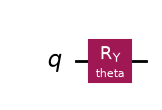

In [4]:
from qiskit.circuit import Parameter

THETA = Parameter("theta")
# Shape (num_points, num_parameters): one row per theta value.
THETA_VALUES = np.linspace(0, np.pi, 7).reshape(-1, 1)

qubits = QuantumRegister(1, name="q")
state = QuantumCircuit(qubits, name="ry_state")
state.ry(THETA, qubits[0])
state.draw("mpl")

### Operator

$Z + X$ as a `SparsePauliOp`, and its exact expectation value at each
$\theta$. The two terms are not qubit-wise commuting, so the Sampler part
needs two circuits.

The second observable is the penalty Hamiltonian
$H_{\text{penalty}} = \tfrac12(I + Z_1Z_0)$ in the state $|{+}{+}\rangle$. By
hand: $|{+}{+}\rangle$ gives each of the four bitstrings the amplitude
$\tfrac12$, so by the Born rule for several qubits each has probability
$\tfrac14$. $Z_1Z_0$ is $+1$ on two of them and $-1$ on the other two, so
$\langle Z_1Z_0\rangle = 0$ and $\langle H_{\text{penalty}}\rangle = \tfrac12$.
That is the average penalty over four equally likely bitstrings, two of which
cost 1.

In [5]:
observable = SparsePauliOp(["Z", "X"], coeffs=[1.0, 1.0])
print([(p, float(c.real)) for p, c in observable.to_list()])
exact = np.cos(THETA_VALUES[:, 0]) + np.sin(THETA_VALUES[:, 0])

penalty = SparsePauliOp.from_list([("II", 0.5), ("ZZ", 0.5)])
plus_plus = QuantumCircuit(2, name="plus_plus")
plus_plus.h([0, 1])
exact_penalty = Statevector(plus_plus).expectation_value(penalty).real
print("exact <penalty> on |++>:", round(exact_penalty, 3))

[('Z', 1.0), ('X', 1.0)]
exact <penalty> on |++>: 0.5


### Execution, part A: the Sampler, by hand

One circuit measures $Z$ directly, and one applies $H$ first so the Z-basis
measurement acts as an X-basis measurement. `with_measurement` builds each
one: `state.copy` makes a copy of the state circuit, `add_register` adds a
one-bit classical register to the copy, and `measure(0, bits)` measures
qubit 0 into that bit. Each PUB is `(circuit, THETA_VALUES)`, so all seven
angles travel in one PUB, and the parameter survives transpiling.

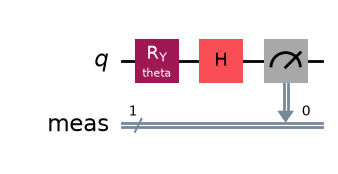

In [6]:
def with_measurement(state, basis):
    circuit = state.copy(name=f"measure_{basis}")
    bits = ClassicalRegister(1, name="meas")
    circuit.add_register(bits)
    if basis == "X":
        circuit.h(0)
    circuit.measure(0, bits)
    return circuit


def expectation_from_counts(counts):
    n0, n1 = counts.get("0", 0), counts.get("1", 0)
    return (n0 - n1) / (n0 + n1)


def sampler_std(z_counts, x_counts):
    variance = 0.0
    for counts in (z_counts, x_counts):
        variance += (1 - expectation_from_counts(counts) ** 2) / sum(counts.values())
    return float(np.sqrt(variance))


sampler_results = {}
for target in targets:
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    isa_z = pass_manager.run(with_measurement(state, "Z"))
    isa_x = pass_manager.run(with_measurement(state, "X"))
    sampler_pubs = [(isa_z, THETA_VALUES), (isa_x, THETA_VALUES)]
    sampler_results[target.label] = target.wait(
        target.sampler.run(sampler_pubs, shots=SETTINGS.shots)
    )

with_measurement(state, "X").draw("mpl")

### Execution, part B: the Estimator

Transpile the circuits with **no** measurements, rewrite each observable for
the transpiled layout, and build one PUB per circuit:
`(circuit, observable, THETA_VALUES)` for the sweep and `(circuit, penalty)`
for $|{+}{+}\rangle$.

In [7]:
estimator_results = {}
for target in targets:
    if sampler_results[target.label] is None:
        continue  # the Sampler job failed; do not submit another
    pass_manager = generate_preset_pass_manager(
        backend=target.backend, optimization_level=1
    )
    isa_state = pass_manager.run(state)
    isa_plus_plus = pass_manager.run(plus_plus)
    estimator_pubs = [
        (isa_state, observable.apply_layout(isa_state.layout), THETA_VALUES),
        (isa_plus_plus, penalty.apply_layout(isa_plus_plus.layout)),
    ]
    estimator_results[target.label] = target.wait(
        target.estimator.run(estimator_pubs, precision=SETTINGS.precision)
    )

### Analysis

For the Sampler, `data.meas` holds one set of shots per $\theta$, and
`get_counts(i)` picks the $i$-th. Each term's expectation value comes from
Example 1 and its standard error from Example 3; the two independent runs add
in variance. For the Estimator, `result[0].data.evs` and `.stds` hold one
value per $\theta$.

In [8]:
by_hand, by_hand_std, estimates = {}, {}, {}
for label, result in sampler_results.items():
    if result is None:
        continue
    z_bits, x_bits = (r.data.meas for r in result)
    points = range(len(THETA_VALUES))
    z_counts = [z_bits.get_counts(i) for i in points]
    x_counts = [x_bits.get_counts(i) for i in points]
    by_hand[label] = np.array([
        expectation_from_counts(zc) + expectation_from_counts(xc)
        for zc, xc in zip(z_counts, x_counts)
    ])
    by_hand_std[label] = np.array([
        sampler_std(zc, xc) for zc, xc in zip(z_counts, x_counts)
    ])

for label, result in estimator_results.items():
    if result is None:
        continue
    estimates[label] = (np.asarray(result[0].data.evs), np.asarray(result[0].data.stds))
    penalty_ev = float(result[1].data.evs)
    penalty_std = float(result[1].data.stds)
    print(f"{label}: <penalty> on |++> = {penalty_ev:.3f} +/- {penalty_std:.3f}"
          "   (exact 0.500)")

for label in by_hand:
    print(f"\n{label}: <Z + X>, each measured value +/- its standard error")
    print(f"  {'theta/pi':>8s}  {'exact':>6s}  {'Sampler':>15s}  {'Estimator':>15s}")
    for i, theta in enumerate(THETA_VALUES[:, 0]):
        s = f"{by_hand[label][i]:+.3f} +/- {by_hand_std[label][i]:.3f}"
        e = (f"{estimates[label][0][i]:+.3f} +/- {estimates[label][1][i]:.3f}"
             if label in estimates else "n/a")
        print(f"  {theta / np.pi:8.3f}  {exact[i]:+6.3f}  {s:>15}  {e:>15}")

aer: <penalty> on |++> = 0.515 +/- 0.020   (exact 0.500)

aer: <Z + X>, each measured value +/- its standard error
  theta/pi   exact          Sampler        Estimator
     0.000  +1.000  +0.997 +/- 0.016  +0.996 +/- 0.020
     0.167  +1.366  +1.359 +/- 0.016  +1.357 +/- 0.020
     0.333  +1.366  +1.376 +/- 0.016  +1.348 +/- 0.020
     0.500  +1.000  +1.007 +/- 0.016  +1.015 +/- 0.020
     0.667  +0.366  +0.359 +/- 0.016  +0.373 +/- 0.020
     0.833  -0.366  -0.361 +/- 0.016  -0.391 +/- 0.020
     1.000  -1.000  -0.997 +/- 0.016  -0.964 +/- 0.020


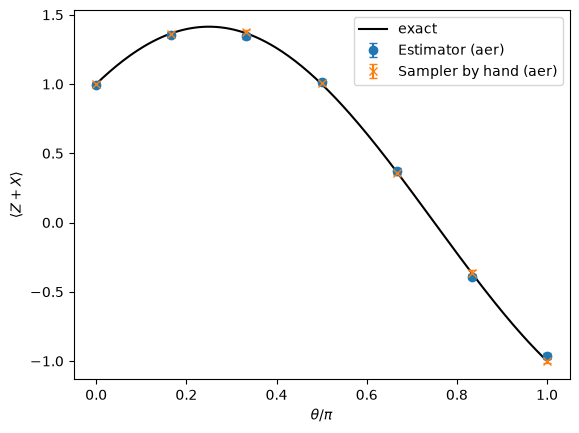

In [9]:
fig, ax = plt.subplots()
x = THETA_VALUES[:, 0] / np.pi
fine = np.linspace(0, 1, 200)
ax.plot(fine, np.cos(np.pi * fine) + np.sin(np.pi * fine), "k-", label="exact")
for label, (evs, stds) in estimates.items():
    ax.errorbar(x, evs, yerr=stds, fmt="o", capsize=3, label=f"Estimator ({label})")
for label, values in by_hand.items():
    ax.errorbar(x, values, yerr=by_hand_std[label], fmt="x", capsize=3,
                label=f"Sampler by hand ({label})")
ax.set_xlabel(r"$\theta / \pi$")
ax.set_ylabel(r"$\langle Z + X \rangle$")
ax.legend()
plt.show()

Both methods recover $\cos\theta + \sin\theta$, and the penalty comes out
near 0.5. The Sampler's standard error is about 0.016 at every $\theta$.
The variance of the $Z$ term is $1 - \cos^2\theta = \sin^2\theta$ and that of
the $X$ term is $1 - \sin^2\theta = \cos^2\theta$, so they always add to 1 and
the standard error of the sum is $\sqrt{1/4096} = 0.016$. The Estimator's are
all 0.020 on Aer, the requested precision. As the scatter rule of
Notebook 00 predicts, most points sit within twice their standard error of
the exact curve, and an occasional point a little farther out is chance. The Sampler needed an extra $H$
and a combination of counts by hand; the Estimator did that bookkeeping and
reported the uncertainty.

## Exercises

1. A Z-basis measurement of 4096 shots gives 2200 zeros and 1896 ones.
   Estimate $\langle Z\rangle$ and its standard error.
2. Compute $\langle Z\rangle$ and $\langle X\rangle$ for $R_y(2\pi/3)|0\rangle$.
3. How many Sampler circuits, under the qubit-wise rule, does $Z + X + Y$
   need? And $Z_1Z_0 + Z_0 + X_1X_0$?
4. The Estimator on hardware is asked for a precision of 0.005. Roughly how
   many shots must it spend on one Pauli string, in the worst case
   $\langle P\rangle = 0$?
5. Notebook 08's hopping operator is $K = \tfrac12(X_0X_1 + Y_0Y_1)$. Compute
   $\langle K\rangle$ for $|01\rangle$ and for $\tfrac{1}{\sqrt2}(|01\rangle - |10\rangle)$
   with `Statevector.expectation_value`. How many Sampler circuits would
   measure it?
6. True or false: if $\langle Z\rangle = 0.3$ for some state, a Z-basis
   measurement of that state returns 0.3 on some shots. Give the reason.
7. (hardware) Set `skip_hardware=False` in the Setup cell and run the
   notebook on `ibm_rensselaer`. At each $\theta$, is the difference between
   the Sampler and the Estimator larger than their combined standard error,
   $\sqrt{\sigma_S^2 + \sigma_E^2}$, judged by the scatter rule of Notebook 00?
   If so, which one is closer to the exact value, and what does the
   error-mitigation caveat suggest about why?

## What you can now do

1. Compute $\langle Z\rangle$, $\langle X\rangle$ and $\langle Z + X\rangle$
   from amplitudes, and from counts with $(n_0 - n_1)/N$ after the right
   change of basis.
2. Give the standard error $\sqrt{(1 - \langle P\rangle^2)/N}$ of a measured
   Pauli expectation value, and combine independent terms in variance.
3. Group Pauli strings into qubit-wise commuting sets and count the circuits
   a sum needs.
4. Measure an observable with the Estimator, with `apply_layout`, and compare
   it with the Sampler result.

## Solutions

**Check, expectation values.** $|-\rangle = (|0\rangle - |1\rangle)/\sqrt2$
has $P(0) = P(1) = \tfrac12$, so $\langle Z\rangle = 0$. It is the eigenvector
of $X$ with eigenvalue $-1$, so every X-basis shot gives $-1$ and
$\langle X\rangle = -1$.

**Check, standard error.** The worst case is $\langle P\rangle = 0$, with
standard error $1/\sqrt N$. $1/\sqrt N \le 0.005$ needs $\sqrt N \ge 200$,
so $N \ge 40\,000$ shots.

**Check, which terms can share a circuit.** One. $\langle I\rangle = 1$
needs nothing, and $Z_1Z_0$ comes from one Z-basis circuit.

**Exercise 1.** $\langle Z\rangle \approx (2200 - 1896)/4096 = 304/4096 = 0.0742$.
Variance $1 - 0.0742^2 = 0.9945$; standard error $\sqrt{0.9945/4096} = 0.0156$.
So $\langle Z\rangle = 0.074 \pm 0.016$. **Check.** The result is about 4.8
standard errors from 0, far more than random scatter explains, so the state is
close to an equal superposition of $|0\rangle$ and $|1\rangle$ but very
probably not exactly one.

**Exercise 2.** By Example 2, $\langle Z\rangle = \cos(2\pi/3) = -0.5$ and
$\langle X\rangle = \sin(2\pi/3) = \sqrt3/2 \approx 0.866$. **Check.**
$\langle Z\rangle^2 + \langle X\rangle^2 = 0.25 + 0.75 = 1$, as for every
state $R_y(\theta)|0\rangle$, which lies on the circle through $|0\rangle$,
$|+\rangle$, $|1\rangle$ and $|-\rangle$.

**Exercise 3.** $Z$, $X$ and $Y$ on one qubit are pairwise not qubit-wise
commuting, so three circuits: Z basis, X basis, Y basis. For
$Z_1Z_0 + Z_0 + X_1X_0$: $Z_1Z_0$ and $Z_0$ share a Z-basis circuit;
$X_1X_0$ differs from both on qubit 0, so it needs its own (X basis on both
qubits). Two circuits.

**Exercise 4.** Standard error $\sqrt{(1 - 0)/N} \le 0.005$ needs
$N \ge 1/0.005^2 = 40\,000$ shots for that one string. A Hamiltonian with
many terms spends shots on every group, which is why precision is expensive
on hardware.

**Exercise 5.** `Statevector.from_label("01").expectation_value(K)` gives 0:
on $|01\rangle$, $K$ gives $|10\rangle$, which is orthogonal to $|01\rangle$.
For $\tfrac{1}{\sqrt2}(|01\rangle - |10\rangle)$ it gives $-1$, the
ground-state energy found in Notebook 08. $X_0X_1$ and $Y_0Y_1$ are not
qubit-wise commuting, so the Sampler needs two circuits: X basis on both
qubits, and Y basis on both qubits.

**Exercise 6.** False. Every shot returns $+1$ or $-1$. $\langle Z\rangle = 0.3$
means that $P(0) - P(1) = 0.3$, so $P(0) = 0.65$ and $P(1) = 0.35$; the
average of many shots is 0.3, but no single shot is.

**Exercise 7.** Two kinds of hardware error act on the Sampler's values.
Gate errors, and readout errors that flip a result in either direction, mix
in wrong $\pm1$ results at random, which shrinks each Pauli expectation value
toward 0. The readout effect of Notebook 00 is one-sided: a 1 is misread as 0
more often, which adds $+1$ results and pushes the measured $\langle Z\rangle$
(and, after the $H$, the measured $\langle X\rangle$) up, toward $+1$. The
Estimator's default readout-error mitigation removes much of both readout
effects but not the gate errors. Judge each difference with the combined
standard error $\sqrt{\sigma_S^2 + \sigma_E^2}$ (with $\sigma_S$ the
Sampler's standard error and $\sigma_E$ the Estimator's) and the scatter rule
of Notebook 00: a difference of more than three times it is real, not shot
noise. If the Estimator is the closer one, the most likely reason is its
readout-error mitigation, which the Sampler counts do not have.

## Terms introduced in this notebook

| Term | Meaning |
|---|---|
| observable | a Hermitian operator that is measured; each shot returns one of its eigenvalues |
| expectation value $\langle O\rangle$ | $\langle\psi\vert O\vert\psi\rangle = \sum_\lambda \lambda P(\lambda)$, the average result over many shots |
| standard error | the typical distance between an average of $N$ shots and the exact value: $\sqrt{\mathrm{variance}/N}$; for a Pauli, $\sqrt{(1-\langle P\rangle^2)/N}$ |
| commuting observables | Hermitian operators with $AB = BA$ (commute is defined in Notebook 02); they share eigenvectors, so one measurement gives both |
| qubit-wise commuting | two Pauli strings whose letters on every qubit are equal or include $I$; one circuit measures both |
| Estimator | the primitive that takes a circuit without measurements and an observable, and returns `evs` and `stds` |
| precision | the target standard error given to the Estimator; on hardware it sets the number of shots |
| physical qubit | one of the actual qubits on the chip, with its own number |
| layout | the transpiler's record of which physical qubit plays each circuit qubit |
| error mitigation | processing that corrects measured values for known hardware errors; readout-error mitigation corrects for misread 0s and 1s |